# Imports

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy import ndimage
from skimage.filters import threshold_otsu

# Mapa s slikami (deluje iz 09_vaje/ in iz 09_vaje/resitve/)
GRADIVO = Path("navodila/Gradivo") if Path("navodila").exists() else Path("../navodila/Gradivo")
rng = np.random.default_rng(1)

# Funkcije

In [2]:
def nalozi(ime, nacin=cv2.IMREAD_UNCHANGED):
    """Naloži sliko. OpenCV vrne kanale v vrstnem redu BGR(A), zato jih preuredimo v RGB(A)."""
    img = cv2.imread(str(GRADIVO / ime), nacin)
    if img.ndim == 3 and img.shape[2] == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    elif img.ndim == 3 and img.shape[2] == 4:
        img = cv2.cvtColor(img, cv2.COLOR_BGRA2RGBA)
    return img


def opisi(img):
    """Višina, širina, število kanalov, podatkovni tip in velikost v kB."""
    H, W = img.shape[:2]
    C = 1 if img.ndim == 2 else img.shape[2]
    return {"H": H, "W": W, "kanali": C, "tip": img.dtype, "kB": img.nbytes / 1024}


def svetlost(img, metoda="utezena"):
    """Svetlost piksla iz kanalov R, G, B (float)."""
    R, G, B = [img[:, :, k].astype(float) for k in range(3)]   # pazi na prekoračitev uint8!
    if metoda == "povprecje":
        return (R + G + B) / 3
    if metoda == "utezena":
        return 0.299 * R + 0.587 * G + 0.114 * B
    if metoda == "max":
        return np.maximum(np.maximum(R, G), B)
    if metoda == "min":
        return np.minimum(np.minimum(R, G), B)
    raise ValueError(metoda)


def otsu(I):
    """Otsujev prag za sliko s celoštevilskimi vrednostmi 0..255.
    Razred 0: I <= T, razred 1: I > T. Vrne (T, sigma_b^2 za vse T)."""
    h = np.bincount(I.ravel().astype(int), minlength=256) / I.size
    omega0 = np.cumsum(h)
    mu = np.cumsum(h * np.arange(256))
    with np.errstate(divide="ignore", invalid="ignore"):
        sigma_b = (mu[-1] * omega0 - mu)**2 / (omega0 * (1 - omega0))
    sigma_b = np.nan_to_num(sigma_b)
    return int(np.argmax(sigma_b)), sigma_b


def oznaci(maska, sosedstvo=4):
    """Označevanje povezanih območij (zapolnjevanje s skladom). Vrne (oznake, število območij)."""
    premiki = [(1, 0), (-1, 0), (0, 1), (0, -1)]
    if sosedstvo == 8:
        premiki += [(1, 1), (1, -1), (-1, 1), (-1, -1)]
    H, W = maska.shape
    L = np.zeros((H, W), int)
    k = 0
    for i in range(H):
        for j in range(W):
            if maska[i, j] and L[i, j] == 0:
                k += 1
                L[i, j] = k
                sklad = [(i, j)]
                while sklad:
                    a, b = sklad.pop()
                    for da, db in premiki:
                        x, y = a + da, b + db
                        if 0 <= x < H and 0 <= y < W and maska[x, y] and L[x, y] == 0:
                            L[x, y] = k
                            sklad.append((x, y))
    return L, k


def lastnosti(L, k):
    """Ploščina (število pikslov) in težišče (vrstica, stolpec) vsakega območja 1..k."""
    vr, st = np.indices(L.shape)
    A = np.bincount(L.ravel(), minlength=k + 1)[1:]
    cy = np.bincount(L.ravel(), weights=vr.ravel(), minlength=k + 1)[1:] / A
    cx = np.bincount(L.ravel(), weights=st.ravel(), minlength=k + 1)[1:] / A
    return A, cy, cx

# Testno območje

In [3]:
# P2: svetlost enega piksla
px = np.array([[[200, 50, 50]]], dtype=np.uint8)
print({m: round(float(svetlost(px, m)[0, 0]), 2) for m in ("povprecje", "utezena", "max", "min")})
print("uint8 past:", px[0, 0, 0] + px[0, 0, 1] + px[0, 0, 2])

# P3: Otsu na roke
I_p3 = np.array([1, 1, 2, 7, 8, 8])
T, s = otsu(I_p3)
print("Otsu P3: T =", T, " sigma_b^2(1, 2, 7) =", np.round(s[[1, 2, 7]], 3))

# P4: povezana območja
P4 = np.array([[1, 1, 0, 0, 0],
               [1, 0, 0, 1, 1],
               [0, 0, 1, 0, 1],
               [0, 1, 0, 0, 0],
               [1, 0, 0, 1, 1]], bool)
print("P4: N4 =", oznaci(P4, 4)[1], " N8 =", oznaci(P4, 8)[1])

{'povprecje': 100.0, 'utezena': 94.85, 'max': 200.0, 'min': 50.0}
uint8 past: 44
Otsu P3: T = 2  sigma_b^2(1, 2, 7) = [ 6.125 10.028  6.125]
P4: N4 = 6  N8 = 3


C:\Users\Rene\AppData\Local\Temp\ipykernel_39636\4163305544.py:4: RuntimeWarning: overflow encountered in scalar add
  print("uint8 past:", px[0, 0, 0] + px[0, 0, 1] + px[0, 0, 2])


# Naloga 1 - Slika 3

RGB0.png {'H': 92, 'W': 92, 'kanali': 4, 'tip': dtype('uint8'), 'kB': 33.0625}
RGB.jpg {'H': 256, 'W': 256, 'kanali': 3, 'tip': dtype('uint8'), 'kB': 192.0}
apple.jpg {'H': 183, 'W': 276, 'kanali': 3, 'tip': dtype('uint8'), 'kB': 147.97265625}
Kontrola.png {'H': 1026, 'W': 1024, 'kanali': 1, 'tip': dtype('uint8'), 'kB': 1026.0}


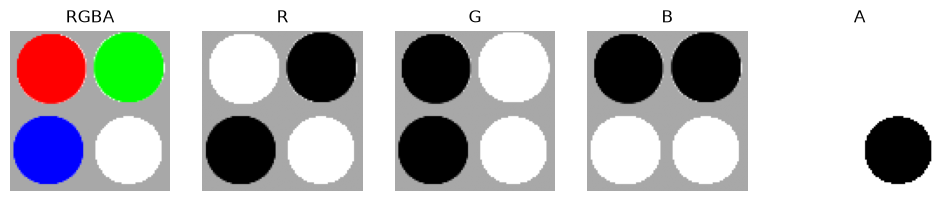

In [4]:
for ime in ("RGB0.png", "RGB.jpg", "apple.jpg", "Kontrola.png"):
    print(ime, opisi(nalozi(ime)))
img = nalozi("RGB0.png")
fig = plt.figure(figsize=(12, 3))
ax = fig.add_subplot(1, 5, 1)
ax.imshow(img)
ax.set_title("RGBA")
for k, ime in enumerate("RGBA"):
    ax = fig.add_subplot(1, 5, k + 2)
    ax.imshow(img[:, :, k], cmap="gray", vmin=0, vmax=255)
    ax.set_title(ime)
for ax in fig.axes:
    ax.axis("off")
plt.show()

# Naloga 2 - Slika 4

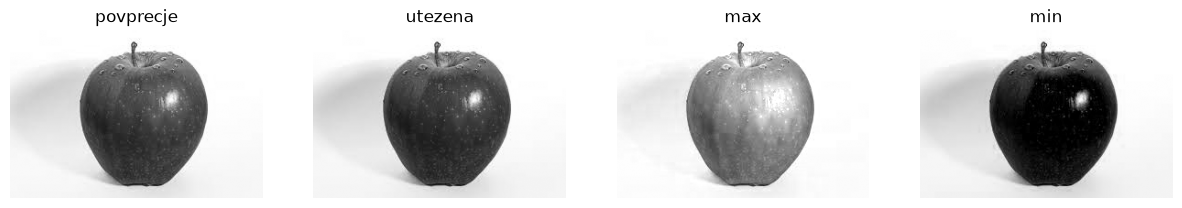

In [5]:
jabolko = nalozi("apple.jpg")
metode = ("povprecje", "utezena", "max", "min")
fig = plt.figure(figsize=(15, 3))
for k, m in enumerate(metode):
    ax = fig.add_subplot(1, 4, k + 1)
    ax.imshow(svetlost(jabolko, m), cmap="gray", vmin=0, vmax=255)
    ax.set_title(m)
    ax.axis("off")
plt.show()

# Naloga 2 - Slika 5

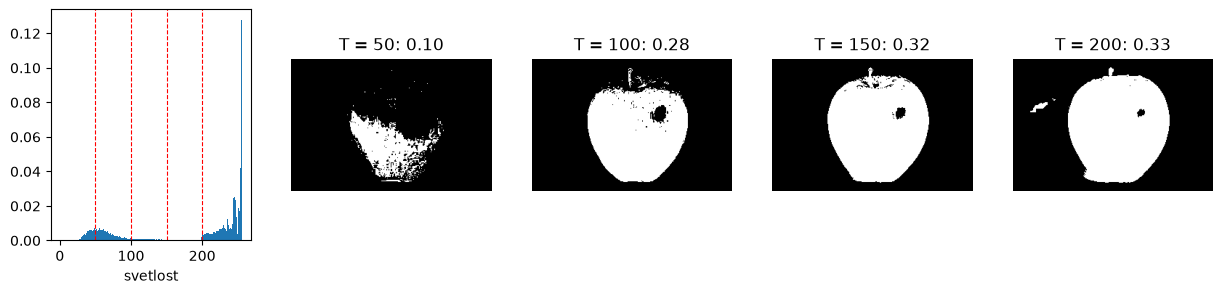

In [6]:
I = svetlost(jabolko, "utezena")
fig = plt.figure(figsize=(15, 3))
ax = fig.add_subplot(1, 5, 1)
ax.hist(I.ravel(), bins=256, range=(0, 256), density=True)
ax.set_xlabel("svetlost")
for k, T in enumerate((50, 100, 150, 200)):
    ax.axvline(T, color="r", ls="--", lw=0.8)
    ax2 = fig.add_subplot(1, 5, k + 2)
    ax2.imshow(I < T, cmap="gray")
    ax2.set_title(f"T = {T}: {np.mean(I < T):.2f}")
    ax2.axis("off")
plt.show()

# Naloga 3 - Slika 6

jabolko: lastni Otsu T = 153, skimage = 153.0, delež ospredja (I <= T) = 0.319
FIG_02: lastni Otsu T = 158, skimage = 158.0, delež ospredja (I <= T) = 0.364


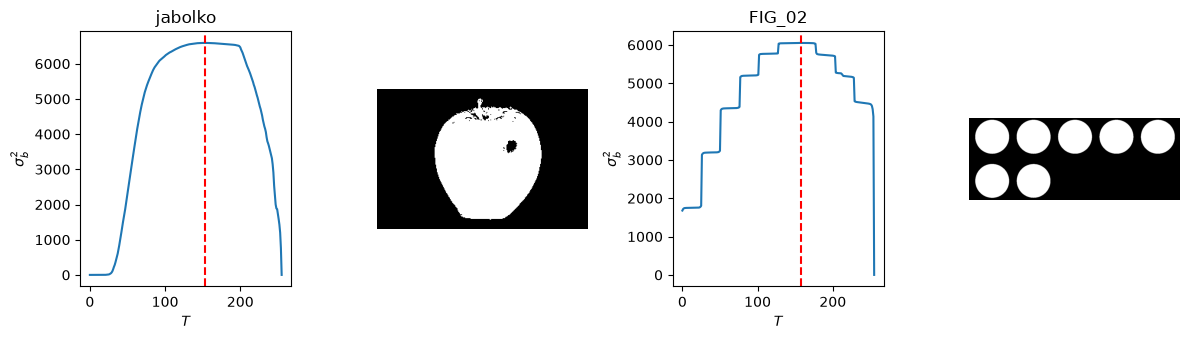

In [7]:
krogi = nalozi("FIG_02.jpg", cv2.IMREAD_GRAYSCALE)
fig = plt.figure(figsize=(12, 3.5))
for k, (ime, slika) in enumerate((("jabolko", np.round(I)), ("FIG_02", krogi))):
    T, s = otsu(slika)
    print(f"{ime}: lastni Otsu T = {T}, skimage = {threshold_otsu(slika.astype(np.uint8)):.1f}, "
          f"delež ospredja (I <= T) = {np.mean(slika <= T):.3f}")
    ax = fig.add_subplot(1, 4, 2 * k + 1)
    ax.plot(s)
    ax.axvline(T, color="r", ls="--")
    ax.set_xlabel("$T$")
    ax.set_ylabel(r"$\sigma_b^2$")
    ax.set_title(ime)
    ax = fig.add_subplot(1, 4, 2 * k + 2)
    ax.imshow(slika <= T, cmap="gray")
    ax.axis("off")
fig.tight_layout()
plt.show()

# Naloga 4 - Slika 7

N4: lastno = 7, scipy = 7
N8: lastno = 5, scipy = 5


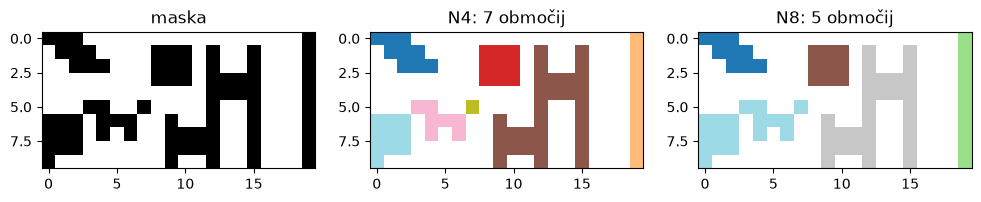

In [8]:
test = nalozi("TEST_1.png", cv2.IMREAD_GRAYSCALE) < 128
fig = plt.figure(figsize=(12, 3))
ax = fig.add_subplot(131)
ax.imshow(test, cmap="gray_r")
ax.set_title("maska")
for k, s in enumerate((4, 8)):
    L, n = oznaci(test, s)
    struk = ndimage.generate_binary_structure(2, 1 if s == 4 else 2)
    print(f"N{s}: lastno = {n}, scipy = {ndimage.label(test, structure=struk)[1]}")
    ax = fig.add_subplot(1, 3, k + 2)
    ax.imshow(np.ma.masked_equal(L, 0), cmap="tab20")
    ax.set_title(f"N{s}: {n} območij")
plt.show()

# Naloga 4 - Slika 8

Naloga1.png: območij = 15, po odstranitvi < 50 px: 15, ploščine: min = 167, max = 177, povprečje = 172 px


Kovanci.png: območij = 31, po odstranitvi < 50 px: 31, ploščine: min = 3729, max = 9049, povprečje = 6614 px


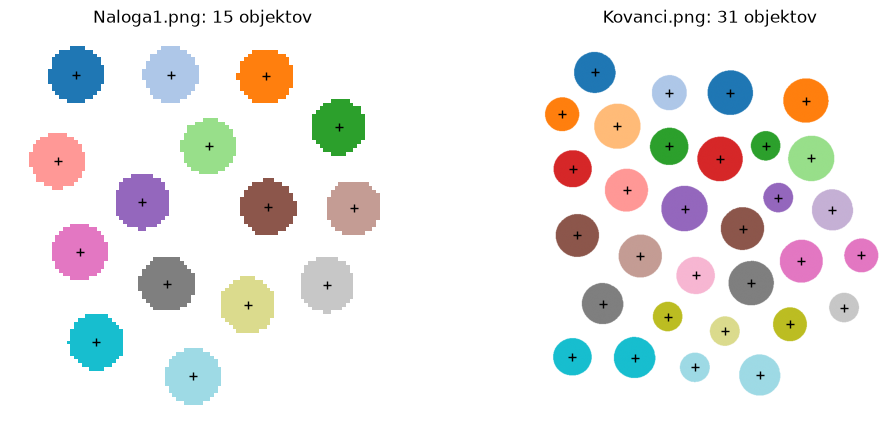

In [9]:
fig = plt.figure(figsize=(12, 5))
for k, (ime, T) in enumerate((("Naloga1.png", 200), ("Kovanci.png", 240))):
    sivo = nalozi(ime, cv2.IMREAD_GRAYSCALE)
    maska = ndimage.binary_fill_holes(sivo < T)
    L, n = oznaci(maska, 8)
    A, cy, cx = lastnosti(L, n)
    velika = A >= 50                       # odstranimo drobne ostanke
    print(f"{ime}: območij = {n}, po odstranitvi < 50 px: {velika.sum()}, "
          f"ploščine: min = {A[velika].min()}, max = {A[velika].max()}, povprečje = {A[velika].mean():.0f} px")
    ax = fig.add_subplot(1, 2, k + 1)
    ax.imshow(np.ma.masked_equal(L, 0), cmap="tab20")
    ax.plot(cx[velika], cy[velika], "k+")
    ax.set_title(f"{ime}: {velika.sum()} objektov")
    ax.axis("off")
plt.show()